<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-scientific-discovery/blob/main/notebooks/lecture-02/universal-approximation-steps.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

<hr/>
# Deep Learning for Scientific Discovery
**Author:** Marcin Płodzień
<hr/>

# Lab 004 — Universal approximation from step functions

## The claim
A neural network with **one hidden layer** and enough neurons can approximate any continuous function $f:[a,b]\to\mathbb{R}$ as accurately as we like
(Cybenko 1989, Hornik 1991). The idea behind the proof fits in one picture:

1. a single neuron with a steep sigmoid is (almost) a **step function**;
2. a sum of shifted and scaled steps is a **staircase**;
3. a staircase with enough steps follows any continuous curve as closely as we like.

This notebook builds each of these pieces in code, then compares the hand-made network with one trained by gradient descent.

> The notebook runs in Google Colab without any installation:
> 1. Go to <https://colab.research.google.com> → *File → Upload notebook*.
> 2. Run cells one by one with **Shift + Enter**, *in order*.
> 3. The required packages (`numpy`, `matplotlib`, `torch`) are pre-installed in Colab.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import io
import ipywidgets as widgets
from IPython.display import display

plt.rcParams["figure.dpi"] = 110
torch.manual_seed(0)
np.random.seed(0)

def live_plot(draw, controls, layout=None):
    # Show sliders + a figure; redraw draw(**slider_values) whenever a slider moves.
    # The figure is sent as a PNG into an Image widget, which works in every Jupyter version and in Colab.
    img = widgets.Image(format="png")
    def update(change=None):
        fig = draw(**{k: c.value for k, c in controls.items()})
        buf = io.BytesIO()
        fig.savefig(buf, format="png", bbox_inches="tight")
        plt.close(fig)
        img.value = buf.getvalue()
    for c in controls.values():
        c.observe(update, names="value")
    update()
    display(widgets.VBox([layout or widgets.VBox(list(controls.values())), img]))

<hr/>
## 1. The target function

We pick a function with no special structure — a few wiggles and a trend:

$$ f(x) = \sin(3x) + 0.3\,x^2 - 0.5\,e^{-4(x-1)^2}, \qquad x\in[-3, 3]. $$

Nothing below uses the formula; the approximations only ever **sample** $f$ at a few points.

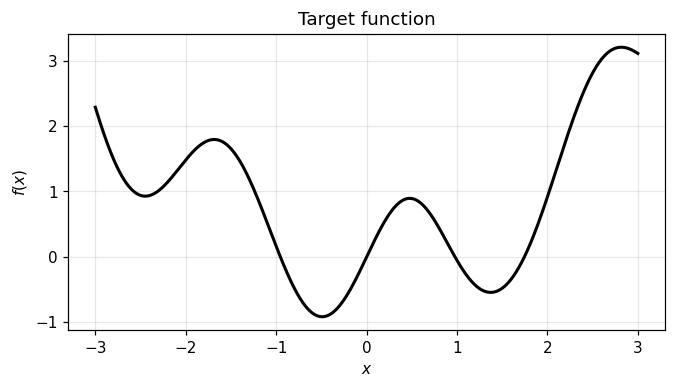

In [2]:
def f(x):
    return np.sin(3 * x) + 0.3 * x**2 - 0.5 * np.exp(-4 * (x - 1)**2)

a, b = -3.0, 3.0
x = np.linspace(a, b, 2000)

plt.figure(figsize=(7, 3.5))
plt.plot(x, f(x), "k", lw=2)
plt.xlabel("$x$"); plt.ylabel("$f(x)$"); plt.title("Target function")
plt.grid(alpha=0.3)
plt.show()

<hr/>
## 2. The building block: a step function

The **Heaviside step function** $\Theta$ switches from 0 to 1 at position $c$:

$$ \Theta(x - c) = \begin{cases} 0, & x < c \\ 1, & x \ge c \end{cases} $$

Multiplying by a height $h$ gives a step of height $h$. Two parameters: **where** it jumps ($c$) and **how much** ($h$).

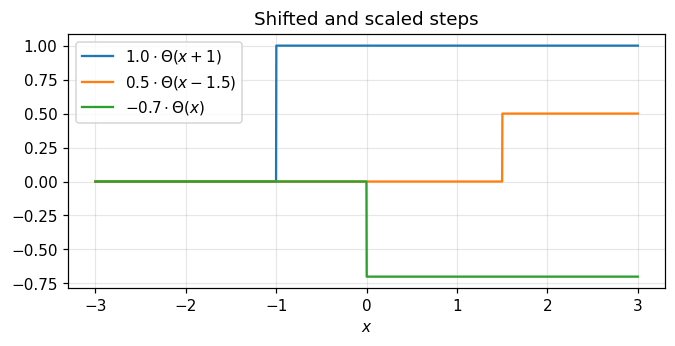

In [3]:
def theta(z):
    return (z >= 0).astype(float)

plt.figure(figsize=(7, 3))
plt.plot(x, 1.0 * theta(x - (-1)), label=r"$1.0\cdot \Theta(x+1)$")
plt.plot(x, 0.5 * theta(x - 1.5), label=r"$0.5\cdot \Theta(x-1.5)$")
plt.plot(x, -0.7 * theta(x - 0), label=r"$-0.7\cdot \Theta(x)$")
plt.xlabel("$x$"); plt.legend(); plt.grid(alpha=0.3); plt.title("Shifted and scaled steps")
plt.show()

### Two steps make a bump
The difference of two steps is a rectangle ("bump") of height $h$ on $[c_1, c_2)$:

$$ h\,[\Theta(x-c_1) - \Theta(x-c_2)]. $$

With bumps we can place a block of any height on any interval — that is already enough to build a histogram-like approximation of any function.

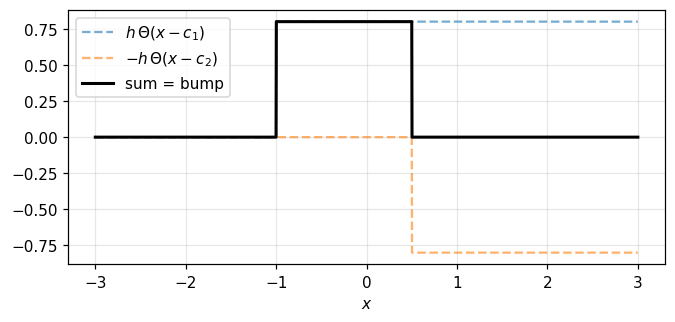

In [4]:
c1, c2, h = -1.0, 0.5, 0.8
plt.figure(figsize=(7, 3))
plt.plot(x, h * theta(x - c1), "--", alpha=0.6, label=r"$h\,\Theta(x-c_1)$")
plt.plot(x, -h * theta(x - c2), "--", alpha=0.6, label=r"$-h\,\Theta(x-c_2)$")
plt.plot(x, h * (theta(x - c1) - theta(x - c2)), "k", lw=2, label="sum = bump")
plt.xlabel("$x$"); plt.legend(); plt.grid(alpha=0.3)
plt.show()

<hr/>
## 3. A staircase approximation

Split $[a,b]$ into $N$ intervals with points $x_0 = a < x_1 < \dots < x_N = b$. Start at the value $f(x_0)$, and at every point $x_i$
add a step whose height is the change of $f$ since the previous point:

$$ f_N(x) = f(x_0) + \sum_{i=1}^{N} \underbrace{\big[f(x_i) - f(x_{i-1})\big]}_{h_i}\; \Theta(x - x_i). $$

For $x\in[x_i, x_{i+1})$ the sum telescopes to exactly $f(x_i)$ — the staircase touches the curve at every grid point.

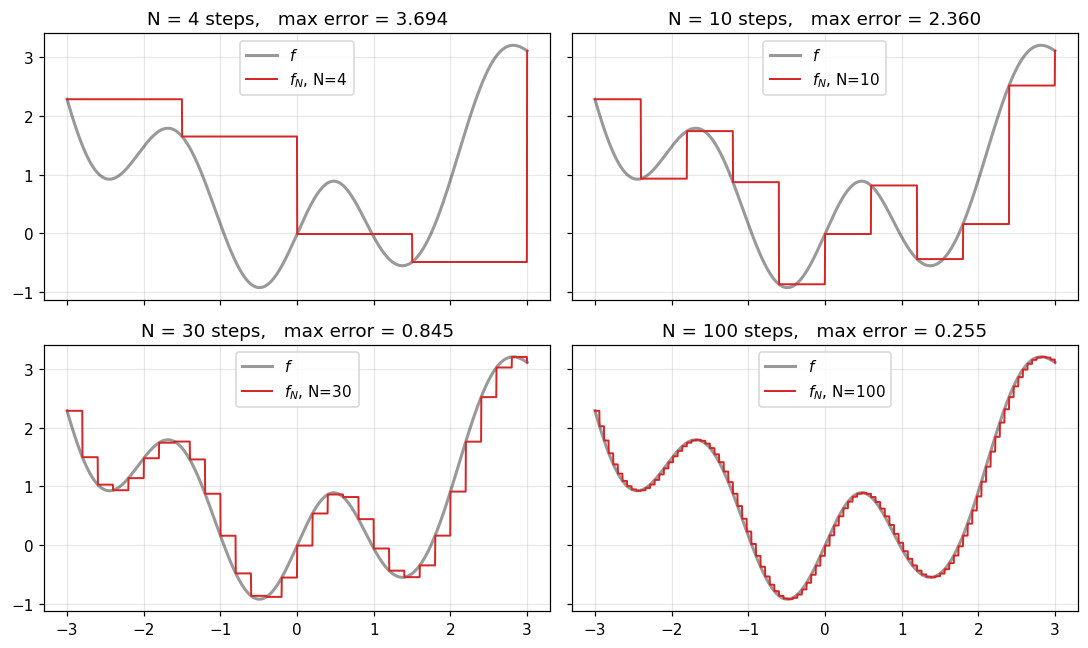

In [5]:
def staircase(x, f, N, a=a, b=b):
    nodes = np.linspace(a, b, N + 1)
    heights = np.diff(f(nodes))                  # h_i = f(x_i) - f(x_{i-1})
    out = np.full_like(x, f(nodes[0]))
    for c, h in zip(nodes[1:], heights):
        out += h * theta(x - c)
    return out

fig, axes = plt.subplots(2, 2, figsize=(10, 6), sharex=True, sharey=True)
for ax, N in zip(axes.flat, [4, 10, 30, 100]):
    ax.plot(x, f(x), "k", lw=2, alpha=0.4, label="$f$")
    ax.plot(x, staircase(x, f, N), "C3", lw=1.3, label=f"$f_N$, N={N}")
    err = np.max(np.abs(f(x) - staircase(x, f, N)))
    ax.set_title(f"N = {N} steps,   max error = {err:.3f}")
    ax.grid(alpha=0.3); ax.legend(loc="upper center")
plt.tight_layout(); plt.show()

### Interactive: choose the number of steps
Move the slider and watch the staircase follow the curve.

In [6]:
def draw_staircase(N):
    y = staircase(x, f, N)
    fig = plt.figure(figsize=(8, 3.8))
    plt.plot(x, f(x), "k", lw=2, alpha=0.4, label="$f$")
    plt.plot(x, y, "C3", label=f"staircase, N = {N}")
    plt.title(f"max error = {np.max(np.abs(f(x) - y)):.3f}")
    plt.xlabel("$x$"); plt.legend(); plt.grid(alpha=0.3); plt.ylim(-2, 4.5)
    return fig

live_plot(draw_staircase, {"N": widgets.IntSlider(value=5, min=1, max=200, description="steps N")})

### How fast does the error shrink?
On an interval of width $\Delta x = (b-a)/N$ the function changes by at most $\max|f'|\,\Delta x$, so

$$ \max_x |f(x) - f_N(x)| \;\le\; \max|f'|\,\frac{b-a}{N} \;\propto\; \frac{1}{N}. $$

More steps → smaller error, without limit. That is the whole universal approximation argument in one dimension.

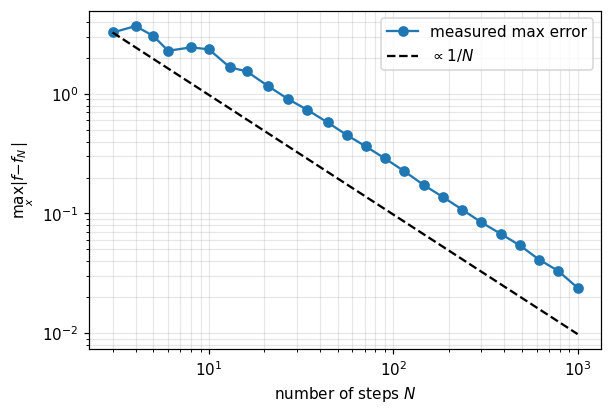

In [7]:
Ns = np.unique(np.logspace(0.5, 3, 25).astype(int))
errs = [np.max(np.abs(f(x) - staircase(x, f, N))) for N in Ns]

plt.figure(figsize=(6, 4))
plt.loglog(Ns, errs, "o-", label="measured max error")
plt.loglog(Ns, errs[0] * Ns[0] / Ns, "k--", label=r"$\propto 1/N$")
plt.xlabel("number of steps $N$"); plt.ylabel(r"$\max_x |f - f_N|$")
plt.legend(); plt.grid(alpha=0.3, which="both")
plt.show()

<hr/>
## 4. From steps to neurons

A neuron computes $\sigma(w x + b)$. With the sigmoid $\sigma(z) = 1/(1+e^{-z})$ and $b = -w c$:

$$ \sigma\big(w(x - c)\big) \;\xrightarrow{\;w\to\infty\;}\; \Theta(x - c). $$

- the **bias** sets *where* the step is ($c = -b/w$),
- the **weight** sets *how sharp* it is,
- the **output weight** of the next layer sets its *height*.

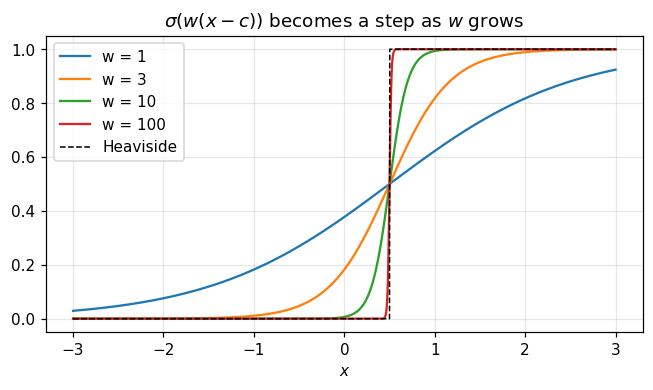

In [8]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

c = 0.5
plt.figure(figsize=(7, 3.5))
for w in [1, 3, 10, 100]:
    plt.plot(x, sigmoid(w * (x - c)), label=f"w = {w}")
plt.plot(x, theta(x - c), "k--", lw=1, label="Heaviside")
plt.xlabel("$x$"); plt.title(r"$\sigma(w(x-c))$ becomes a step as $w$ grows")
plt.legend(); plt.grid(alpha=0.3); plt.show()

### The staircase is a one-hidden-layer network
Replace every $\Theta$ by a steep sigmoid:

$$ \hat f(x) = f(x_0) + \sum_{i=1}^{N} h_i\,\sigma\big(w(x - x_i)\big). $$

This is exactly
`Linear(1, N)` → `Sigmoid` → `Linear(N, 1)`, with

| layer | parameter | value |
|---|---|---|
| hidden | weights | $w$ (all the same) |
| hidden | biases | $-w\,x_i$ |
| output | weights | $h_i = f(x_i) - f(x_{i-1})$ |
| output | bias | $f(x_0)$ |

Below we build this network in PyTorch and **set the weights by hand** — no training.

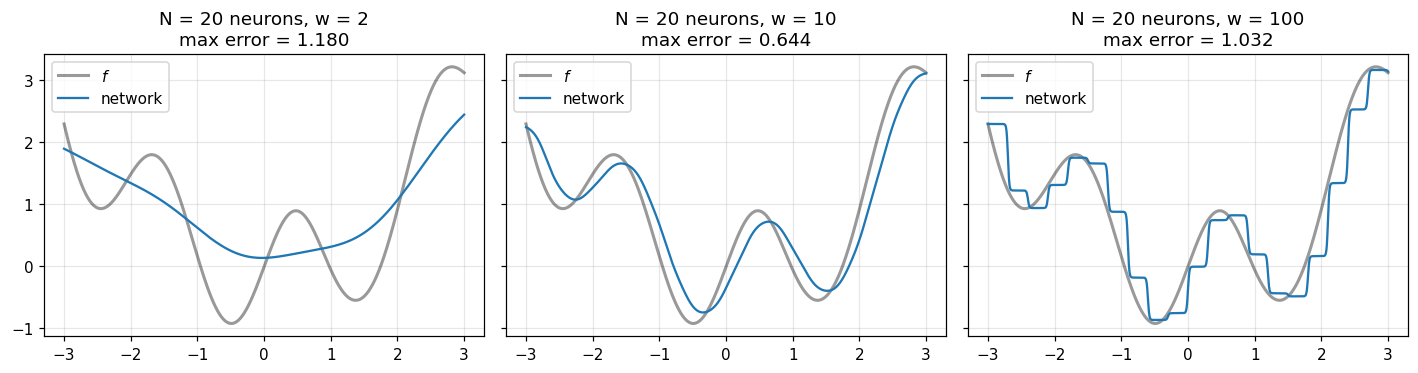

In [9]:
def handmade_network(N, w):
    nodes = np.linspace(a, b, N + 1)
    heights = np.diff(f(nodes))

    net = nn.Sequential(nn.Linear(1, N), nn.Sigmoid(), nn.Linear(N, 1))
    with torch.no_grad():
        net[0].weight[:] = w
        net[0].bias[:]   = torch.tensor(-w * nodes[1:])
        net[2].weight[:] = torch.tensor(heights).unsqueeze(0)
        net[2].bias[:]   = f(nodes[0])
    return net

def evaluate(net, x):
    with torch.no_grad():
        return net(torch.tensor(x, dtype=torch.float32).unsqueeze(1)).squeeze(1).numpy()

N = 20
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5), sharey=True)
for ax, w in zip(axes, [2, 10, 100]):
    y_net = evaluate(handmade_network(N, w), x)
    ax.plot(x, f(x), "k", lw=2, alpha=0.4, label="$f$")
    ax.plot(x, y_net, "C0", label="network")
    ax.set_title(f"N = {N} neurons, w = {w}\nmax error = {np.max(np.abs(f(x) - y_net)):.3f}")
    ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.show()

Observations:
- $w$ too small: steps are blurred into each other, the network is too smooth.
- $w$ large: we recover the staircase.
- There is a sweet spot — the sigmoid's own smoothness interpolates *between* grid points better than a sharp jump.

### Look inside: each neuron contributes one step

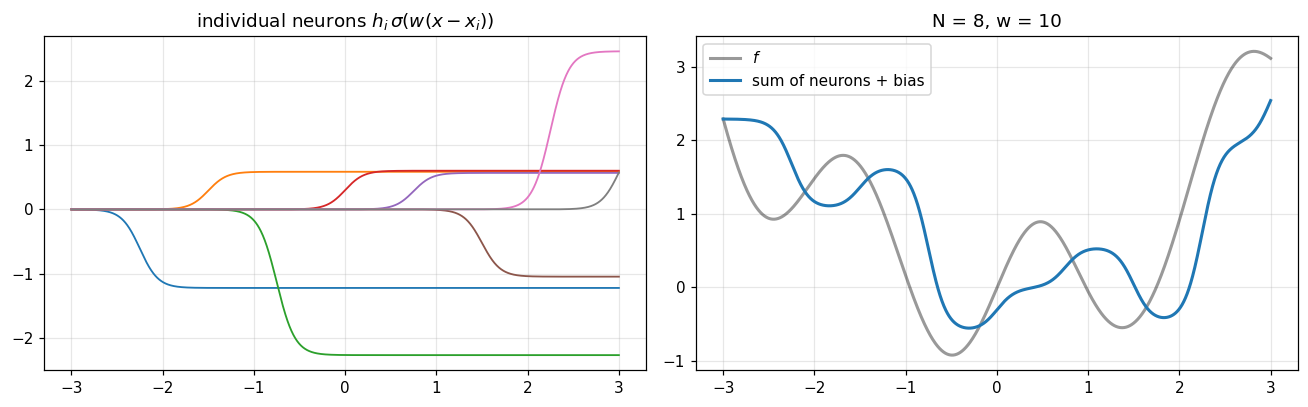

In [10]:
N, w = 8, 10
net = handmade_network(N, w)
xt = torch.tensor(x, dtype=torch.float32).unsqueeze(1)
with torch.no_grad():
    hidden = net[1](net[0](xt)).numpy()              # (len(x), N) activations
    contrib = hidden * net[2].weight.numpy()          # scaled by output weights

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for i in range(N):
    axes[0].plot(x, contrib[:, i], lw=1.2)
axes[0].set_title(r"individual neurons $h_i\,\sigma(w(x-x_i))$"); axes[0].grid(alpha=0.3)

axes[1].plot(x, f(x), "k", lw=2, alpha=0.4, label="$f$")
axes[1].plot(x, contrib.sum(1) + net[2].bias.item(), "C0", lw=2, label="sum of neurons + bias")
axes[1].set_title(f"N = {N}, w = {w}"); axes[1].legend(); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

### Interactive: number of neurons and steepness
Two sliders: the number of hidden neurons $N$ and the common weight $w$ (steepness). Left: every neuron's contribution;
right: their sum, which is the network output.

In [11]:
def draw_network(N, w):
    net = handmade_network(N, w)
    with torch.no_grad():
        contrib = net[1](net[0](xt)).numpy() * net[2].weight.numpy()
    y_net = contrib.sum(1) + net[2].bias.item()

    fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
    axes[0].plot(x, contrib, lw=1)
    axes[0].set_title(f"{N} neurons, each $h_i\\,\\sigma(w(x-x_i))$"); axes[0].grid(alpha=0.3)
    axes[1].plot(x, f(x), "k", lw=2, alpha=0.4, label="$f$")
    axes[1].plot(x, y_net, "C0", lw=2, label="network")
    axes[1].set_title(f"N = {N}, w = {w:.1f},   max error = {np.max(np.abs(f(x) - y_net)):.3f}")
    axes[1].set_ylim(-2, 4.5); axes[1].legend(); axes[1].grid(alpha=0.3)
    fig.tight_layout()
    return fig

live_plot(draw_network, {
    "N": widgets.IntSlider(value=8, min=1, max=100, description="neurons N"),
    "w": widgets.FloatLogSlider(value=10, base=10, min=-0.5, max=2.5, step=0.05, description="weight w"),
})

<hr/>
### Your turn: be the optimiser
Now **you** set every parameter of a network

$$ \hat f(x) = v_0 + \sum_{i=1}^{N} v_i\,\Theta(w_i x + b_i), $$

built from **Θ step functions** (switch to `sigmoid` with the toggle to compare).

- The slider **N** sets the number of neurons; one row of sliders appears per neuron.
- For neuron $i$: weight $w_i$ (steepness; negative = step down), bias $b_i$ (the step sits at $x = -b_i/w_i$), output weight $v_i$ (height).
- With Θ only the **sign** of $w_i$ (step up or down) and the location $-b_i/w_i$ matter — the size of $w_i$ is irrelevant.
  With the sigmoid, $|w_i|$ also sets how sharp the step is.
- **The sliders start at the loss-minimising values** for the current $N$ and activation (and jump back there whenever
  $N$ or the activation changes). Move any slider and watch the MSE rise above the optimum — the title shows by how many percent.
- **set to optimum** goes back to the best parameters; **set to staircase** loads the uniform hand-made construction from above
  (compare its MSE with the optimum!); **reset heights** sets all $v_i = 0$.

How the optimum is found: with Θ the network is piecewise constant with $N$ jumps, and the best positions of the jumps are found
exactly by dynamic programming (every piece takes the mean of $f$ on it). For the sigmoid we start from that solution and refine
all $w_i, b_i, v_i$ with gradient descent (Adam).

Things to try: Which neuron hurts most when you move it? Is the loss more sensitive to the position $-b_i/w_i$ or to the height $v_i$?
How does the optimal MSE fall with $N$?

In [12]:
N_MAX = 20
W_THETA = 10.0                                        # for Θ only sign(w) matters; any positive value works

# ---------- loss-minimising parameters -------------------------------------------------
x_fit = np.linspace(a, b, 600)                        # grid on which the MSE is minimised
y_fit = f(x_fit)

def optimal_theta(N):
    # A Θ-network with N neurons is piecewise constant with N jumps. The best such function
    # (minimal MSE) is found exactly by dynamic programming over all positions of the jumps:
    # every piece takes the mean of f on it, and we pick the cut points with the smallest total error.
    n = len(y_fit)
    S1 = np.concatenate([[0], np.cumsum(y_fit)])
    S2 = np.concatenate([[0], np.cumsum(y_fit**2)])
    i, j = np.meshgrid(np.arange(n + 1), np.arange(n + 1), indexing="ij")
    with np.errstate(divide="ignore", invalid="ignore"):
        cost = S2[j] - S2[i] - (S1[j] - S1[i])**2 / (j - i)   # squared error of one piece x_fit[i:j]
    cost[j <= i] = np.inf
    D, back = cost[0], []                             # D[j] = best error of x_fit[:j] with k pieces
    for k in range(N):
        tot = D[:, None] + cost
        back.append(np.argmin(tot, axis=0))
        D = np.min(tot, axis=0)
    cuts, j = [], n                                   # backtrack the cut positions
    for k in reversed(range(N)):
        j = back[k][j]; cuts.append(j)
    cuts = sorted(cuts)
    edges = [0] + cuts + [n]
    means = [y_fit[p:q].mean() for p, q in zip(edges[:-1], edges[1:])]
    centers = [(x_fit[c - 1] + x_fit[c]) / 2 for c in cuts]
    return [(W_THETA, -W_THETA * c, h) for c, h in zip(centers, np.diff(means))], means[0]

def optimal_sigmoid(N, n_steps=1500):
    # start from the Θ optimum (steep sigmoids) and refine all parameters with Adam
    params, v0 = optimal_theta(N)
    w0 = 2 * N / (b - a) + 1
    W = torch.tensor([p[0] / W_THETA * w0 for p in params], requires_grad=True)
    B = torch.tensor([p[1] / W_THETA * w0 for p in params], requires_grad=True)
    V = torch.tensor([p[2] for p in params], requires_grad=True)
    V0 = torch.tensor(float(v0), requires_grad=True)
    xt_, yt_ = torch.tensor(x_fit), torch.tensor(y_fit)
    opt = torch.optim.Adam([W, B, V, V0], lr=0.02)
    for _ in range(n_steps):
        loss = ((V0 + (V * torch.sigmoid(xt_[:, None] * W + B)).sum(1) - yt_)**2).mean()
        opt.zero_grad(); loss.backward(); opt.step()
        with torch.no_grad():                         # keep the values inside the slider ranges
            W.clamp_(-30, 30); B.clamp_(-90, 90); V.clamp_(-5, 5); V0.clamp_(-4, 4)
    return [(w.item(), bb.item(), v.item()) for w, bb, v in zip(W, B, V)], V0.item()

optimum_cache = {}
def optimum(act_name, N):
    if (act_name, N) not in optimum_cache:
        optimum_cache[(act_name, N)] = optimal_theta(N) if act_name == "Θ step" else optimal_sigmoid(N)
    return optimum_cache[(act_name, N)]

# ---------- widgets ---------------------------------------------------------------------
def neuron_sliders(i):
    return {"w": widgets.FloatSlider(value=W_THETA, min=-30, max=30, step=0.01, description=f"w{i+1}"),
            "b": widgets.FloatSlider(value=0.0, min=-90, max=90, step=0.01, description=f"b{i+1}"),
            "v": widgets.FloatSlider(value=0.0, min=-5, max=5, step=0.01, description=f"v{i+1}")}

neurons    = [neuron_sliders(i) for i in range(N_MAX)]
rows       = [widgets.HBox([n["w"], n["b"], n["v"]]) for n in neurons]
slider_N   = widgets.IntSlider(value=4, min=1, max=N_MAX, description="neurons N", continuous_update=False)
slider_v0  = widgets.FloatSlider(value=0.0, min=-4, max=4, step=0.01, description="offset v0")
activation = widgets.ToggleButtons(options=["Θ step", "sigmoid"], value="Θ step", description="activation")
btn_opt    = widgets.Button(description="set to optimum", button_style="success")
btn_stair  = widgets.Button(description="set to staircase")
btn_reset  = widgets.Button(description="reset heights")
rows_box   = widgets.VBox()
img        = widgets.Image(format="png")
paused     = False                                    # avoids redrawing 3N times when a button sets many sliders

def act_fn():
    return theta if activation.value == "Θ step" else sigmoid

def network(params, v0, act):
    return v0 + sum(v * act(w * x + bb) for w, bb, v in params)

def redraw(change=None):
    if paused:
        return
    N = slider_N.value
    act = act_fn()
    sym = "\\Theta" if activation.value == "Θ step" else "\\sigma"
    params = [tuple(neurons[i][k].value for k in "wbv") for i in range(N)]
    y = network(params, slider_v0.value, act)
    mse = np.mean((f(x) - y)**2)
    mse_opt = np.mean((f(x) - network(*optimum(activation.value, N), act))**2)

    fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
    for i, (w_i, b_i, v_i) in enumerate(params):
        loc = -b_i / w_i if w_i != 0 else np.nan
        axes[0].plot(x, v_i * act(w_i * x + b_i), label=f"neuron {i+1}: step at x = {loc:.2f}")
    axes[0].set_title(f"individual neurons $v_i\\,{sym}(w_i x + b_i)$"); axes[0].grid(alpha=0.3)
    if N <= 8:
        axes[0].legend(fontsize=8)
    axes[1].plot(x, f(x), "k", lw=2, alpha=0.4, label="$f$")
    axes[1].plot(x, y, "C2", lw=2, label=f"your network ({N} neurons)")
    axes[1].set_title(f"MSE = {mse:.4f}   (optimum {mse_opt:.4f},  +{100 * (mse / mse_opt - 1):.1f}%)")
    axes[1].set_ylim(-2, 4.5); axes[1].legend(); axes[1].grid(alpha=0.3)
    fig.tight_layout()
    buf = io.BytesIO(); fig.savefig(buf, format="png", bbox_inches="tight"); plt.close(fig)
    img.value = buf.getvalue()

def set_many(values, v0):
    global paused
    paused = True
    for i, (w_i, b_i, v_i) in enumerate(values):
        neurons[i]["w"].value, neurons[i]["b"].value, neurons[i]["v"].value = w_i, b_i, v_i
    slider_v0.value = v0
    paused = False
    redraw()

def on_optimum(_=None):
    set_many(*optimum(activation.value, slider_N.value))

def on_N(change):
    rows_box.children = rows[:slider_N.value]
    on_optimum()                                      # new N -> start again from the optimum

def on_staircase(_):
    N = slider_N.value
    nodes = np.linspace(a, b, N + 1)
    w = min(2 * N / (b - a), 30)
    set_many([(w, -w * c, h) for c, h in zip(nodes[1:], np.diff(f(nodes)))], f(nodes[0]))

def on_reset(_):
    set_many([(n["w"].value, n["b"].value, 0.0) for n in neurons[:slider_N.value]], 0.0)

slider_N.observe(on_N, names="value")
activation.observe(on_optimum, names="value")
slider_v0.observe(redraw, names="value")
for n in neurons:
    for s in n.values():
        s.observe(redraw, names="value")
btn_opt.on_click(on_optimum)
btn_stair.on_click(on_staircase)
btn_reset.on_click(on_reset)

rows_box.children = rows[:slider_N.value]
on_optimum()
display(widgets.VBox([activation, widgets.HBox([slider_N, slider_v0]),
                      widgets.HBox([btn_opt, btn_stair, btn_reset]), rows_box, img]))

### Error vs number of neurons
For a fair comparison the steepness has to grow with $N$ (the steps get narrower): we take $w = 2N/(b-a)$, i.e. every
sigmoid rises over about one grid spacing.

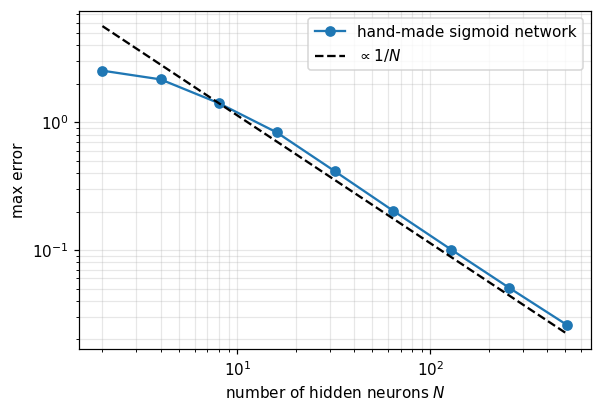

In [13]:
Ns = [2, 4, 8, 16, 32, 64, 128, 256, 512]
err_net = []
for N in Ns:
    w = 2 * N / (b - a)
    err_net.append(np.max(np.abs(f(x) - evaluate(handmade_network(N, w), x))))

plt.figure(figsize=(6, 4))
plt.loglog(Ns, err_net, "o-", label="hand-made sigmoid network")
plt.loglog(Ns, err_net[2] * Ns[2] / np.array(Ns), "k--", label=r"$\propto 1/N$")
plt.xlabel("number of hidden neurons $N$"); plt.ylabel("max error")
plt.legend(); plt.grid(alpha=0.3, which="both"); plt.show()

<hr/>
## 5. Hand-made vs trained

The construction above proves that a good set of weights **exists**. It says nothing about whether gradient descent finds it.
Let us train the same architecture from a random initialisation, using only samples of $f$, and compare.

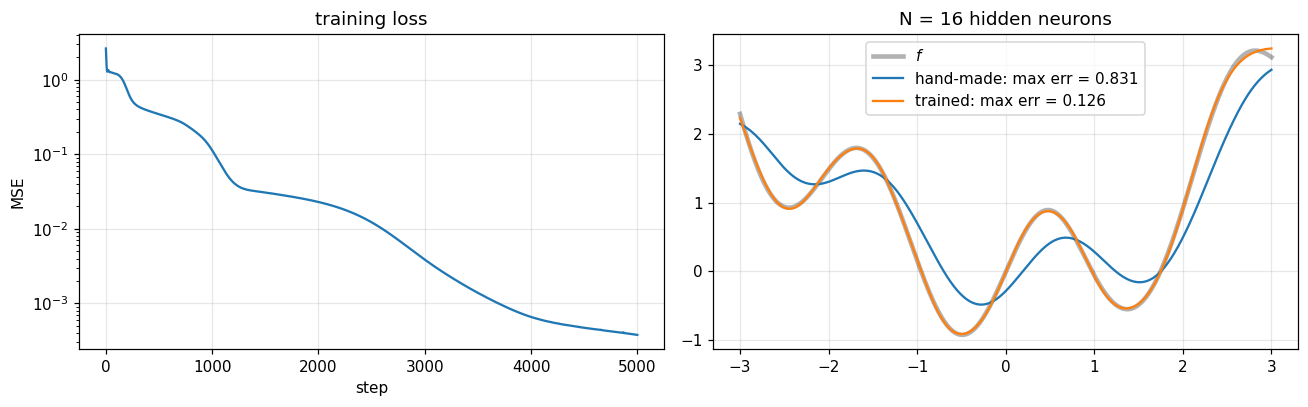

In [14]:
def train_network(N, n_steps=5000, lr=1e-2, seed=0):
    torch.manual_seed(seed)
    net = nn.Sequential(nn.Linear(1, N), nn.Sigmoid(), nn.Linear(N, 1))
    x_train = torch.linspace(a, b, 400).unsqueeze(1)
    y_train = torch.tensor(f(x_train.numpy()), dtype=torch.float32)
    opt = torch.optim.Adam(net.parameters(), lr=lr)
    losses = []
    for step in range(n_steps):
        loss = ((net(x_train) - y_train)**2).mean()
        opt.zero_grad(); loss.backward(); opt.step()
        losses.append(loss.item())
    return net, losses

N = 16
net_trained, losses = train_network(N)
net_hand = handmade_network(N, w=2 * N / (b - a))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].semilogy(losses); axes[0].set_xlabel("step"); axes[0].set_ylabel("MSE")
axes[0].set_title("training loss"); axes[0].grid(alpha=0.3)

axes[1].plot(x, f(x), "k", lw=3, alpha=0.3, label="$f$")
for net, name in [(net_hand, "hand-made"), (net_trained, "trained")]:
    y_net = evaluate(net, x)
    axes[1].plot(x, y_net, label=f"{name}: max err = {np.max(np.abs(f(x) - y_net)):.3f}")
axes[1].set_title(f"N = {N} hidden neurons"); axes[1].legend(); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

What does the trained network do with its neurons? It is not restricted to equal spacing, equal steepness, or the heights
$f(x_i)-f(x_{i-1})$. Each neuron's step location is $c_i = -b_i / w_i$ — let us see where training put them.

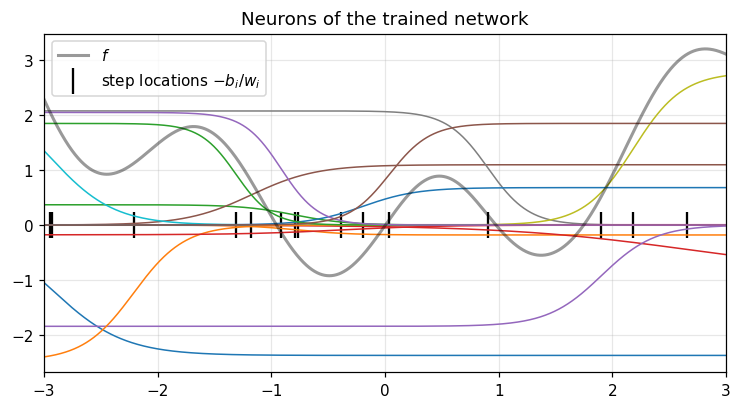

steepness |w_i| : [0.04 1.25 2.32 3.18 3.49 3.58 4.21 4.24 4.28 4.3  4.47 4.6  5.55 5.58
 6.07 6.33]


In [15]:
W = net_trained[0].weight.detach().squeeze().numpy()
B = net_trained[0].bias.detach().numpy()
centers = -B / W

with torch.no_grad():
    contrib = net_trained[1](net_trained[0](xt)).numpy() * net_trained[2].weight.numpy()

fig, ax = plt.subplots(figsize=(8, 4))
for i in range(N):
    ax.plot(x, contrib[:, i], lw=1)
ax.plot(x, f(x), "k", lw=2, alpha=0.4, label="$f$")
ax.scatter(centers[(centers > a) & (centers < b)], np.zeros(np.sum((centers > a) & (centers < b))),
           marker="|", s=300, c="k", label="step locations $-b_i/w_i$")
ax.set_xlim(a, b); ax.set_title("Neurons of the trained network"); ax.legend(); ax.grid(alpha=0.3)
plt.show()

print("steepness |w_i| :", np.round(np.sort(np.abs(W)), 2))

The trained neurons are placed and shaped **adaptively**: more of them where $f$ curves strongly, with different steepnesses,
and some may sit outside $[a,b]$ and act as smooth trends. That is why a trained network typically needs far fewer neurons than the
uniform staircase for the same accuracy.
<hr/>
## 6. Bonus: two dimensions need a second layer of steps

In 2D the analogue of a bump is a **tower**: a block of height $h$ over a rectangle $[c_1,c_2)\times[d_1,d_2)$.
Four steps (two in $x$, two in $y$) add up to 4 only inside the rectangle; a second step with threshold $3.5$ keeps exactly that region:

$$ \text{tower}(x,y) = \Theta\Big( \Theta(x-c_1) - \Theta(x-c_2) + \Theta(y-d_1) - \Theta(y-d_2) + 2 - 3.5 \Big) \cdot h $$

(the $+2$ accounts for the two negative steps being $-1$ outside — inside the rectangle the sum is $1+0+1+0+2 = 4$).
A sum of towers on a grid approximates any $f(x,y)$ — this is a network with **two** hidden layers of step neurons.

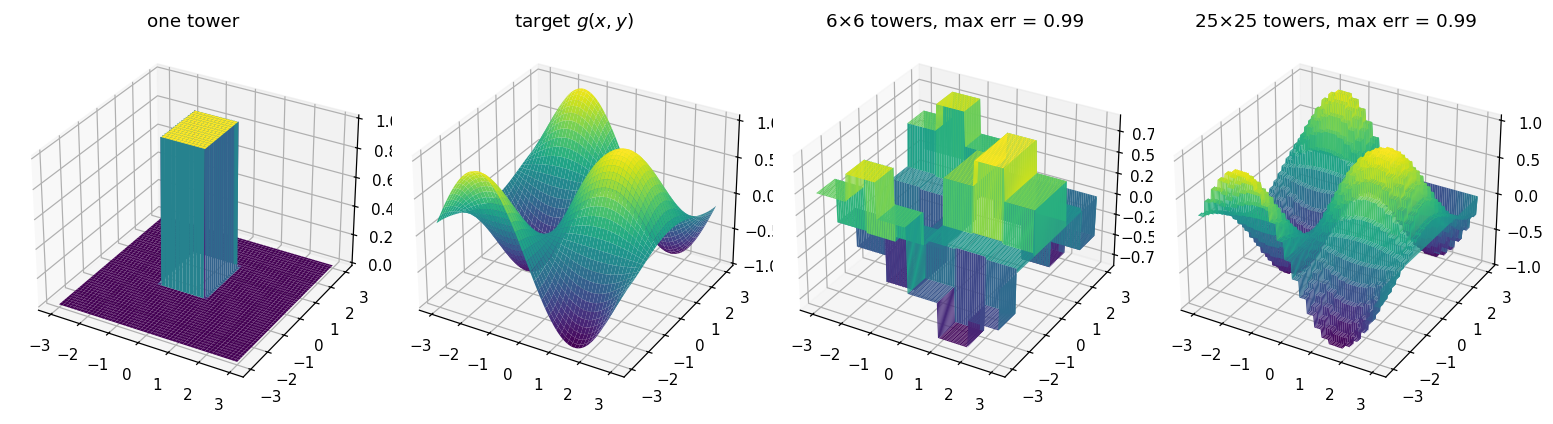

In [16]:
def tower(X, Y, c1, c2, d1, d2):
    s = theta(X - c1) - theta(X - c2) + theta(Y - d1) - theta(Y - d2) + 2
    return theta(s - 3.5)

def g(X, Y):
    return np.sin(X) * np.cos(Y) + 0.3 * np.exp(-(X**2 + Y**2))

L = 3.0
xs = np.linspace(-L, L, 200)
X, Y = np.meshgrid(xs, xs)

def tower_approx(X, Y, n):
    edges = np.linspace(-L, L, n + 1)
    mids = 0.5 * (edges[1:] + edges[:-1])
    out = np.zeros_like(X)
    for i in range(n):
        for j in range(n):
            out += g(mids[i], mids[j]) * tower(X, Y, edges[i], edges[i+1], edges[j], edges[j+1])
    return out

fig = plt.figure(figsize=(14, 4))
ax = fig.add_subplot(1, 4, 1, projection="3d")
ax.plot_surface(X, Y, tower(X, Y, -1, 0.5, -0.5, 1.5), cmap="viridis", rstride=4, cstride=4)
ax.set_title("one tower")
ax = fig.add_subplot(1, 4, 2, projection="3d")
ax.plot_surface(X, Y, g(X, Y), cmap="viridis", rstride=4, cstride=4)
ax.set_title("target $g(x,y)$")
for k, n in enumerate([6, 25]):
    ax = fig.add_subplot(1, 4, 3 + k, projection="3d")
    Z = tower_approx(X, Y, n)
    ax.plot_surface(X, Y, Z, cmap="viridis", rstride=2, cstride=2)
    ax.set_title(f"{n}×{n} towers, max err = {np.max(np.abs(Z - g(X, Y))):.2f}")
plt.tight_layout(); plt.show()

The price: $n$ towers per dimension in $d$ dimensions means $n^d$ towers — the **curse of dimensionality** for this naive
construction. Real networks on real data do far better than this worst-case count, because they learn where to put their neurons
(Section 5) and because real data have structure.
<hr/>
## Summary

- One neuron with a steep sigmoid ≈ one step: bias = location, weight = sharpness, output weight = height.
- A sum of $N$ steps reproduces $f$ with error $\propto 1/N$ — no limit on accuracy.
- Therefore a single hidden layer is **in principle** enough (universal approximation theorem).
- The theorem guarantees existence, not efficiency or trainability: gradient descent finds different, adaptive solutions.
- In $d$ dimensions the naive construction needs $\sim n^d$ neurons.

## Exercises
1. Replace $f$ by $|x|$, by a function with a jump (e.g. `np.sign(x)`), and by $\sin(10x)$. Which needs the most steps, and why?
2. Replace the sigmoid with `nn.ReLU()`. Show that $\text{ReLU}(x - c_1) - \text{ReLU}(x - c_2)$ is a ramp, and build a piecewise-linear
   interpolant of $f$ by hand. How does its error scale with $N$?
3. Repeat Section 5 for $N = 4, 8, 32, 64$ and plot the max error of the trained and hand-made networks on the same log-log plot.
4. Evaluate the trained network on $x\in[-5,5]$ (outside the training interval). What happens, and why does the construction give no guarantee there?